# 03 · Hidden Markov Model — Daily Demand Regimes
**Component 3: implementation of a Hidden Markov Model.** Run `01_Create_Dataset` first.

Reads `dataset/daily_series.csv` · creates `results/03_hmm/`.

In [1]:
# ---- Only on Google Colab (skip on your own computer) ----
# !pip install -q hmmlearn
# from google.colab import drive; drive.mount("/content/drive")
# %cd /content/drive/MyDrive/QuickCommerce_ML_Project_Final

import os, json, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import norm
from sklearn.mixture import GaussianMixture
from hmmlearn.hmm import GaussianHMM
import joblib
warnings.filterwarnings("ignore")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
DATE = "%d-%m-%Y"

def inr(x):
    # Indian digit grouping: 113390 -> 1,13,390
    s = f"{abs(x):.0f}"; head, tail = s[:-3], s[-3:]; parts = []
    while len(head) > 2:
        parts.insert(0, head[-2:]); head = head[:-2]
    if head: parts.insert(0, head)
    return ("-" if x < 0 else "") + ",".join(parts + [tail])

# chart style — colour-blind-safe palette in fixed order
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 9.5, "font.size": 8.5, "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 1.5, "figure.dpi": 110, "legend.frameon": False,
})

OUT = "results/03_hmm"                      # every file this notebook creates goes here
os.makedirs(OUT, exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=240, bbox_inches="tight")
    plt.show()

In [2]:
daily = pd.read_csv("dataset/daily_series.csv", index_col="order_date", parse_dates=["order_date"])
print(f"Daily table: {len(daily)} days ({daily.index.min():{DATE}} to {daily.index.max():{DATE}})")
daily.head()

Daily table: 638 days (01-01-2025 to 30-09-2026)


,orders,event,dow,late_rate,rain_share,trend,expected,demand_index
order_date,,,,,,,,
2025-01-01,35,New Year's Day,Wednesday,0.171,0.029,41.000,39.305,-0.116
2025-01-02,36,Regular day,Thursday,0.206,0.000,41.000,39.443,-0.091
2025-01-03,35,Regular day,Friday,0.147,0.000,41.000,38.784,-0.103
2025-01-04,43,Regular day,Saturday,0.190,0.116,42.000,47.102,-0.091
2025-01-05,60,Regular day,Sunday,0.169,0.000,43.000,48.005,0.223


## 3.1 Why an HMM fits this problem
The network moves through **situations that are not written in the data**: ordinary days, the monsoon period when
rain slows riders, and short festival peaks. Each day we only *observe* the effects — how unusual demand was and how
many deliveries were late. An HMM is designed exactly for this:
- a **hidden state** $s_t$ (the regime) that changes over time following a **Markov chain** — tomorrow's regime depends
  on today's (monsoon days come in long runs; festival peaks last two or three days);
- an **observation** $o_t$ generated by the current state (each regime has its own typical demand and lateness).

Clustering the days instead would ignore their order in time; the HMM uses it (compared in notebook 04).

## 3.2 Model definition
| Element | In this project |
|---|---|
| Hidden states $S$ | 3 regimes, named after fitting: *Normal*, *Monsoon / disrupted*, *Festival peak* |
| Observations $O_t$ | 2 numbers per day: demand index, late-delivery rate |
| Initial probabilities $\pi_i = P(s_1 = i)$ | learned |
| Transition probabilities $a_{ij} = P(s_{t+1}=j \mid s_t=i)$ | learned 3 × 3 matrix |
| Emission probabilities $b_i(o_t) = P(o_t \mid s_t=i)$ | Gaussian for each state: mean and variance of demand index and late rate |
| Training | Baum–Welch (EM) algorithm, 20 random starts, best log-likelihood kept |
| Decoding | Viterbi algorithm — the most likely sequence of hidden states |

### Choosing the number of hidden states

,log-likelihood,parameters,AIC ↓,BIC ↓
states,,,,
2,"1,379.055",11,"-2,736.110","-2,687.068"
3,"1,465.684",20,"-2,891.367","-2,802.201"
4,"1,497.404",31,"-2,932.809","-2,794.600"
5,"1,515.317",44,"-2,942.634","-2,746.467"


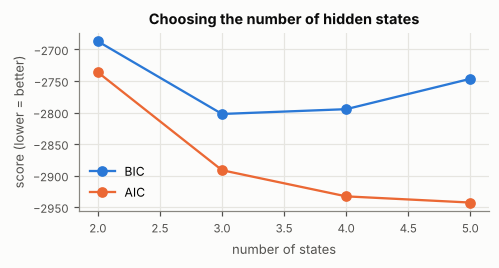

BIC is lowest for 3 states -> chosen


In [3]:
OBS = ["demand_index", "late_rate"]
O = daily[OBS].values

def fit_hmm(obs, n_states, restarts=20):
    best = None
    for s in range(restarts):
        m = GaussianHMM(n_components=n_states, covariance_type="diag", n_iter=500, tol=1e-4, random_state=s).fit(obs)
        ll = m.score(obs)
        if best is None or ll > best[0]:
            best = (ll, m)
    return best

def n_params(n, d=2):           # initial (n-1) + transitions n(n-1) + means n·d + variances n·d
    return (n - 1) + n * (n - 1) + 2 * n * d

rows = []
for k in range(2, 6):
    ll, m = fit_hmm(O, k)
    rows.append({"states": k, "log-likelihood": ll, "parameters": n_params(k),
                 "AIC ↓": 2 * n_params(k) - 2 * ll, "BIC ↓": n_params(k) * np.log(len(O)) - 2 * ll})
nsel = pd.DataFrame(rows).set_index("states")
nsel.to_csv(f"{OUT}/state_selection.csv")
display(nsel)
fig, ax = plt.subplots(figsize=(4.6, 2.5))
ax.plot(nsel.index, nsel["BIC ↓"], color=BLUE, marker="o", label="BIC"); ax.plot(nsel.index, nsel["AIC ↓"], color=ORANGE, marker="o", label="AIC")
ax.set(title="Choosing the number of hidden states", xlabel="number of states", ylabel="score (lower = better)"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig(fig, "state_selection")
N_STATES = int(nsel["BIC ↓"].idxmin())
print(f"BIC is lowest for {N_STATES} states -> chosen")

BIC balances fit against complexity (it penalises every extra parameter); its minimum gives the number of states.

*Why two observations?* The check below fits the same 3-state HMM to the demand index **alone**: it then separates
ordinary days by calendar period rather than by situation, because the business was small in early 2025 and its daily
numbers were noisier (a size artefact, not a real regime). Adding the late-delivery rate gives regimes that matter for
operations.

In [4]:
_, hmm_1d = fit_hmm(daily[["demand_index"]].values, 3)
lab_1d = pd.Series(hmm_1d.predict(daily[["demand_index"]].values), index=daily.index)
check_1d = pd.crosstab(daily.index.to_period("Q").astype(str), lab_1d)
check_1d.columns = [f"state {i} (mean {hmm_1d.means_[i, 0]:+.2f}, std {np.sqrt(hmm_1d.covars_[i, 0, 0]):.2f})" for i in check_1d.columns]
print("Demand index only — days of each quarter in each state:")
check_1d

Demand index only — days of each quarter in each state:


,"state 0 (mean +0.00, std 0.09)","state 1 (mean +0.01, std 0.13)","state 2 (mean +0.48, std 0.17)"
row_0,,,
2025Q1,13,75,2
2025Q2,0,91,0
2025Q3,21,71,0
2025Q4,87,0,5
2026Q1,85,0,5
2026Q2,91,0,0
2026Q3,89,0,3


## 3.3 Training and the learned probabilities

In [5]:
t0 = time.perf_counter()
HMM_LL, hmm = fit_hmm(O, N_STATES)
HMM_TIME = time.perf_counter() - t0
# name states from their emission means: highest demand = festival peak; of the rest, higher lateness = monsoon
means = pd.DataFrame(hmm.means_, columns=OBS)
peak = means.demand_index.idxmax()
monsoon = means.drop(peak).late_rate.idxmax()
SNAMES = {peak: "Festival peak", monsoon: "Monsoon / disrupted"}
SNAMES.update({i: "Normal" for i in range(N_STATES) if i not in SNAMES})
SORDER = ["Normal", "Monsoon / disrupted", "Festival peak"]
SCOL = dict(zip(SORDER, [BLUE, AQUA, ORANGE]))
idx = [k for name in SORDER for k, v in SNAMES.items() if v == name]
print(f"Training (Baum–Welch, 20 starts): {HMM_TIME:.1f} s | log-likelihood of best model = {HMM_LL:.1f}")

start = pd.Series(hmm.startprob_[idx], index=SORDER, name="initial probability π")
trans = pd.DataFrame(hmm.transmat_[np.ix_(idx, idx)], index=[f"from {s}" for s in SORDER], columns=[f"to {s}" for s in SORDER])
emis = pd.DataFrame({"demand index mean": hmm.means_[idx, 0], "demand index std": np.sqrt(hmm.covars_[idx, 0, 0]),
                     "≈ demand vs normal": [f"{np.expm1(v):+.0%}" for v in hmm.means_[idx, 0]],
                     "late rate mean": hmm.means_[idx, 1], "late rate std": np.sqrt(hmm.covars_[idx, 1, 1])}, index=SORDER)
start.to_frame().to_csv(f"{OUT}/initial_probabilities.csv")
trans.round(4).to_csv(f"{OUT}/transition_matrix.csv")
emis.round(4).to_csv(f"{OUT}/emission_parameters.csv")
display(start.to_frame()); display(trans.round(3)); display(emis.round(3))

Training (Baum–Welch, 20 starts): 0.7 s | log-likelihood of best model = 1465.7


,initial probability π
Normal,1.000
Monsoon / disrupted,0.000
Festival peak,0.000


,to Normal,to Monsoon / disrupted,to Festival peak
from Normal,0.972,0.005,0.023
from Monsoon / disrupted,0.003,0.981,0.016
from Festival peak,0.279,0.137,0.585


,demand index mean,demand index std,≈ demand vs normal,late rate mean,late rate std
Normal,0.002,0.102,+0%,0.225,0.048
Monsoon / disrupted,0.003,0.099,+0%,0.323,0.053
Festival peak,0.281,0.294,+32%,0.296,0.055


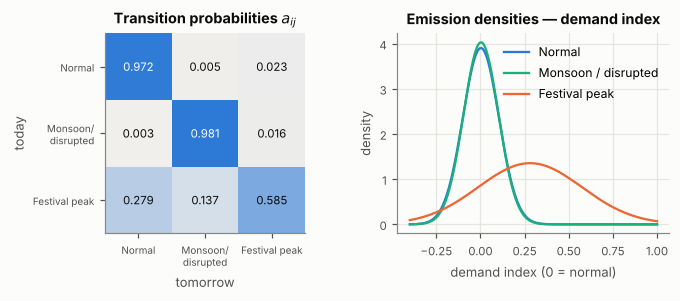

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.8))
blues = LinearSegmentedColormap.from_list("b", ["#f0efec", BLUE])
axes[0].imshow(trans.values, cmap=blues, vmin=0, vmax=1)
axes[0].set_xticks(range(N_STATES)); axes[0].set_xticklabels([s.replace(" / ", "/\n") for s in SORDER], fontsize=6.5)
axes[0].set_yticks(range(N_STATES)); axes[0].set_yticklabels([s.replace(" / ", "/\n") for s in SORDER], fontsize=6.5)
axes[0].set(xlabel="tomorrow", ylabel="today", title="Transition probabilities $a_{ij}$"); axes[0].grid(False)
for i in range(N_STATES):
    for j in range(N_STATES):
        axes[0].text(j, i, f"{trans.values[i, j]:.3f}", ha="center", va="center", fontsize=7.5,
                     color="#fcfcfb" if trans.values[i, j] > 0.6 else INK)
grid_x = np.linspace(-0.4, 1.0, 400)
for name, i in zip(SORDER, idx):
    axes[1].plot(grid_x, norm.pdf(grid_x, hmm.means_[i, 0], np.sqrt(hmm.covars_[i, 0, 0])), color=SCOL[name], label=name)
axes[1].set(title="Emission densities — demand index", xlabel="demand index (0 = normal)", ylabel="density"); axes[1].legend(fontsize=8)
plt.tight_layout(); save_fig(fig, "transitions_and_emissions")

**Emission probabilities as a table.** The emissions are continuous (Gaussian), so the table converts them into
probabilities of observing each *level* of demand and lateness in each state.

In [7]:
DEM_BINS = [-np.inf, np.log(0.9), np.log(1.15), np.inf]; DEM_LBL = ["demand low (< −10%)", "demand normal", "demand high (> +15%)"]
LATE_BINS = [-np.inf, 0.25, 0.30, np.inf];          LATE_LBL = ["late < 25%", "late 25–30%", "late > 30%"]
def level_probs(mu, sd, bins):
    return np.diff(norm.cdf(bins, mu, sd))
emis_tab = pd.DataFrame(
    [np.r_[level_probs(hmm.means_[i, 0], np.sqrt(hmm.covars_[i, 0, 0]), DEM_BINS),
           level_probs(hmm.means_[i, 1], np.sqrt(hmm.covars_[i, 1, 1]), LATE_BINS)] for i in idx],
    index=SORDER, columns=DEM_LBL + LATE_LBL)
emis_tab.round(4).to_csv(f"{OUT}/emission_probabilities.csv")
emis_tab.round(3)

,demand low (< −10%),demand normal,demand high (> +15%),late < 25%,late 25–30%,late > 30%
Normal,0.146,0.765,0.089,0.700,0.240,0.060
Monsoon / disrupted,0.136,0.780,0.084,0.083,0.249,0.667
Festival peak,0.095,0.221,0.684,0.200,0.328,0.472


## 3.4 Decoding the hidden states (Viterbi)

In [8]:
daily["state"] = pd.Series(hmm.predict(O), index=daily.index).map(SNAMES)
post = hmm.predict_proba(O)
daily["p_state"] = post.max(axis=1)
for name, i in zip(SORDER, idx):
    daily[f"p_{name.split()[0].lower()}"] = post[:, i]
counts = daily.state.value_counts().reindex(SORDER)
runs = (daily.state != daily.state.shift()).cumsum()
run_len = daily.groupby(runs).state.agg(["first", "size"])
durations = pd.DataFrame({"days": counts, "share": (counts / len(daily)).map("{:.1%}".format),
                          "expected run (1/(1−a_ii))": [1 / (1 - trans.values[i, i]) for i in range(N_STATES)],
                          "observed average run": run_len.groupby("first")["size"].mean().reindex(SORDER)})
SWITCHES = int((daily.state != daily.state.shift()).sum() - 1)
print(f"Regime switches over {len(daily)} days: {SWITCHES}")
print(f"Average posterior certainty of the decoded state: {daily.p_state.mean():.1%}")
durations.round(1)

Regime switches over 638 days: 19
Average posterior certainty of the decoded state: 97.7%


,days,share,expected run (1/(1−a_ii)),observed average run
Normal,357,56.0%,35.400,51.000
Monsoon / disrupted,258,40.4%,53.800,51.600
Festival peak,23,3.6%,2.400,2.900


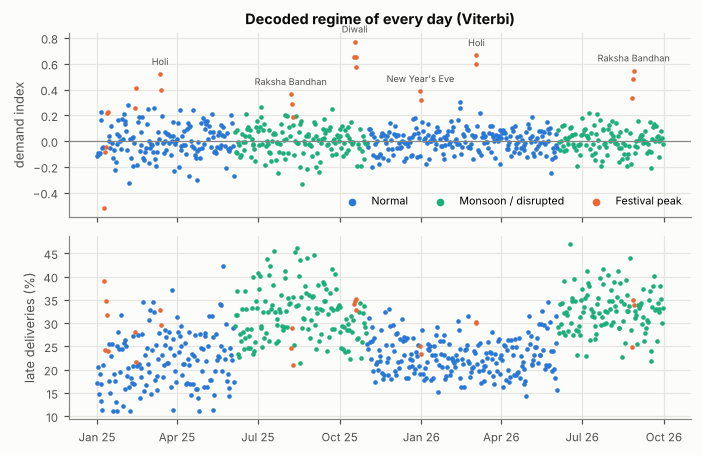

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(6.5, 4.2), sharex=True)
for name in SORDER:
    m = daily.state.eq(name)
    axes[0].scatter(daily.index[m], daily.demand_index[m], s=4, color=SCOL[name], label=name)
    axes[1].scatter(daily.index[m], daily.late_rate[m] * 100, s=4, color=SCOL[name], label=name)
axes[0].axhline(0, color=MUTED, lw=0.8)
axes[0].set(title="Decoded regime of every day (Viterbi)", ylabel="demand index"); axes[0].legend(fontsize=7, ncol=3, markerscale=2)
axes[1].set(ylabel="late deliveries (%)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
lab = daily[daily.event.isin(["Diwali", "Holi", "Raksha Bandhan", "New Year's Eve"])].copy()
lab["occ"] = (lab.event != lab.event.shift()).cumsum()
for _, g in lab.groupby("occ"):
    d = g.demand_index.idxmax()
    axes[0].annotate(g.event.iloc[0], (d, g.demand_index.max()), xytext=(0, 6), textcoords="offset points", fontsize=6, ha="center", color=INK2)
plt.tight_layout(); save_fig(fig, "decoded_regimes")

## 3.5 Interpreting the decoded states

In [10]:
regime_summary = daily.groupby("state")[["orders", "demand_index", "late_rate", "rain_share"]].mean().reindex(SORDER)
regime_summary.round(4).to_csv(f"{OUT}/regime_summary.csv")
print("Average conditions in each decoded regime:"); display(regime_summary.round(3))
print("Decoded regime by month (days):")
by_month = pd.crosstab(daily.index.month, daily.state).reindex(columns=SORDER, fill_value=0)
by_month.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
display(by_month.T)
fest = daily[~daily.event.eq("Regular day")]
fest_tab = fest.assign(date=fest.index.strftime(DATE))[["date", "event", "demand_index", "state", "p_state"]].reset_index(drop=True)
fest_tab.round(3).to_csv(f"{OUT}/festival_days.csv", index=False)
FEST_RECALL = fest.state.eq("Festival peak").mean()
FALSE_PEAKS = int(daily.loc[daily.event.eq("Regular day"), "state"].eq("Festival peak").sum())
print("Festival days and their decoded regime:"); display(fest_tab.round(2))
print(f"Festival days decoded as 'Festival peak': {FEST_RECALL:.0%}  |  regular days decoded as peak: {FALSE_PEAKS}")

Average conditions in each decoded regime:


,orders,demand_index,late_rate,rain_share
state,,,,
Normal,155.176,0.003,0.225,0.088
Monsoon / disrupted,204.721,0.003,0.323,0.516
Festival peak,224.957,0.357,0.296,0.185


Decoded regime by month (days):


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
state,,,,,,,,,,,,
Normal,56,54,58,60,62,7,0,0,0,0,30,30
Monsoon / disrupted,0,0,0,0,0,53,62,56,60,27,0,0
Festival peak,6,2,4,0,0,0,0,6,0,4,0,1


Festival days and their decoded regime:


,date,event,demand_index,state,p_state
0,01-01-2025,New Year's Day,-0.120,Normal,1.000
1,13-02-2025,Valentine's Day,0.250,Festival peak,0.850
2,14-02-2025,Valentine's Day,0.410,Festival peak,0.960
3,13-03-2025,Holi,0.520,Festival peak,1.000
4,14-03-2025,Holi,0.400,Festival peak,1.000
5,07-08-2025,Raksha Bandhan,0.360,Festival peak,0.980
6,08-08-2025,Raksha Bandhan,0.280,Festival peak,0.970
7,09-08-2025,Raksha Bandhan,0.190,Festival peak,0.740
8,17-10-2025,Diwali,0.650,Festival peak,1.000
9,18-10-2025,Diwali,0.770,Festival peak,1.000


Festival days decoded as 'Festival peak': 82%  |  regular days decoded as peak: 5


**What the states mean**
- **Normal** — demand as expected and the fewest late deliveries (about 22%); November to May. Long-lasting (stay
  probability 0.97).
- **Monsoon / disrupted** — demand as expected, but about a third of deliveries are late and about half of the orders
  are placed in rain; June to October. The most persistent regime (0.98) → add riders, extend promised times,
  pre-position stock.
- **Festival peak** — a sudden jump in demand (+32% on average): Diwali, Holi, Raksha Bandhan, New Year's Eve,
  Valentine's Day 2025. It lasts two to three days → build extra stock of sweets, snacks and dairy in advance.

The model was **not** told about rain or festivals. 82% of festival days are decoded as peaks; the misses are small
festivals with a mild rise (Christmas, Valentine's Day 2026, 01-01-2025). The 5 regular days decoded as peaks are
09–13 January 2025 — the noisy first weeks of the data.

## 3.6 Out-of-sample check and tomorrow's regime
Trained on **2025 only**, evaluated on the unseen **2026** days (average log-likelihood per day — higher is better),
and compared with the same Gaussian states **without time dependence** (a Gaussian Mixture Model).

In [11]:
train_mask = daily.index < "2026-01-01"
_, hmm_tr = fit_hmm(O[train_mask], N_STATES)
gmm_tr = GaussianMixture(n_components=N_STATES, covariance_type="diag", n_init=20, random_state=SEED).fit(O[train_mask])
single = GaussianMixture(n_components=1, covariance_type="diag").fit(O[train_mask])
OOS = pd.Series({"HMM (3 states, with transitions)": hmm_tr.score(O[~train_mask]) / (~train_mask).sum(),
                 "Gaussian Mixture (3 states, no transitions)": gmm_tr.score(O[~train_mask]),
                 "Single Gaussian (no states)": single.score(O[~train_mask])}, name="test log-likelihood per day")
OOS.to_frame().round(4).to_csv(f"{OUT}/out_of_sample.csv")
display(OOS.to_frame().round(3))

today = post[-1]
tomorrow = today @ hmm.transmat_
nxt = pd.DataFrame({f"today ({daily.index[-1]:{DATE}})": today[idx],
                    f"tomorrow ({daily.index[-1] + pd.Timedelta(days=1):{DATE}})": tomorrow[idx]}, index=SORDER)
nxt.round(4).to_csv(f"{OUT}/next_day_forecast.csv")
print("Regime probabilities — tomorrow = today × transition matrix:")
nxt.round(3)

,test log-likelihood per day
"HMM (3 states, with transitions)",2.501
"Gaussian Mixture (3 states, no transitions)",2.182
Single Gaussian (no states),2.017


Regime probabilities — tomorrow = today × transition matrix:


,today (30-09-2026),tomorrow (01-10-2026)
Normal,0.000,0.004
Monsoon / disrupted,0.996,0.978
Festival peak,0.003,0.018


## 3.7 Save the HMM files

In [12]:
daily.round(4).to_csv(f"{OUT}/daily_regimes.csv")
joblib.dump({"hmm": hmm, "observations": OBS, "state_names": SNAMES}, f"{OUT}/hmm_model.joblib")
json.dump({"n_states": N_STATES, "log_likelihood": round(HMM_LL, 2), "bic": round(float(nsel.loc[N_STATES, "BIC ↓"]), 2),
           "fit_time_s": round(HMM_TIME, 2), "switches": SWITCHES, "mean_certainty": round(float(daily.p_state.mean()), 4),
           "festival_recall": round(float(FEST_RECALL), 4), "false_peaks": FALSE_PEAKS,
           "oos_hmm": round(float(OOS.iloc[0]), 4), "oos_gmm": round(float(OOS.iloc[1]), 4), "oos_single": round(float(OOS.iloc[2]), 4)},
          open(f"{OUT}/summary.json", "w"), indent=2)
for f in sorted(os.listdir(OUT)):
    print(f"{OUT}/{f}")

results/03_hmm/daily_regimes.csv
results/03_hmm/decoded_regimes.png
results/03_hmm/emission_parameters.csv
results/03_hmm/emission_probabilities.csv
results/03_hmm/festival_days.csv
results/03_hmm/hmm_model.joblib
results/03_hmm/initial_probabilities.csv
results/03_hmm/next_day_forecast.csv
results/03_hmm/out_of_sample.csv
results/03_hmm/regime_summary.csv
results/03_hmm/state_selection.csv
results/03_hmm/state_selection.png
results/03_hmm/summary.json
results/03_hmm/transition_matrix.csv
results/03_hmm/transitions_and_emissions.png
